
## 📑 Table of Contents

1. [🧪 Part 1: Pulse Code Modulation (PCM) & Demodulation](#part-1-pulse-code-modulation-pcm--demodulation)
2. [🧪 Part 2: Direct Sequence Spread Spectrum (DSSS)](#part-2-direct-sequence-spread-spectrum-dsss)
3. [🧪 Part 3: Frequency Hopping Spread Spectrum (FHSS)](#part-3-frequency-hopping-spread-spectrum-fhss)
4. [🧪 Part 4: (2, 1, 2) Convolutional Codes](#part-4-convolutional-codes-2-1-2)
5. [📊 Master Benchmark Summary & Viva Reference](#master-benchmark-summary--viva-reference)

---

### 📦 Prerequisites
Make sure the required Python packages are installed:
```bash
pip install numpy matplotlib scipy
```


---

# Experiment 1 — Pulse Code Modulation (PCM) & Demodulation

**Aim (manual):** Generate Pulse Code Modulation and Demodulation using MATLAB. This notebook implements the same basic stages in Python.

## 1. Theory / principle

**PCM** represents the amplitude of an analog message by a finite binary word at each sampling instant.

**Transmitter:** analog message → low-pass (anti-alias) filter → sampler → quantizer → binary encoder → PCM bits.  
**Receiver:** PCM bits → regeneration/decoder → reconstruction low-pass filter → approximate analog message.

- **Sampling:** Take discrete-time samples of a continuous analog signal.
- **Quantization:** Replace each sample with the nearest allowed amplitude level (finite precision).
- **Encoding:** Assign a binary code to each level; the result is the PCM bitstream.
- **Decoding / reconstruction:** Recover quantized amplitudes and smooth the signal with an LPF.

### Essential formulas

Message signal:

$$x(t) = A\sin(2\pi f_m t)$$

Sampling theorem (for a bandlimited signal):

$$f_s \geq 2f_{\max}$$

For a **uniform** quantizer with $L$ levels, $n$ bits per sample and input range $x_{\min}$ to $x_{\max}$:

$$L=2^n,\qquad \Delta=\frac{x_{\max}-x_{\min}}{L}$$

The PCM bit rate is:

$$R_b=n f_s\quad\text{bits/second}$$

Quantization error:

$$e_q=x-x_q$$


## 2. Values used in the lab manual

| Quantity | Value |
|---|---:|
| Sine amplitude $A$ | $4$ |
| Message frequency $f_m$ | $2\,\mathrm{Hz}$ |
| Sampling frequency $f_s$ | $200\,\mathrm{Hz}$ ($100f_m$) |
| Quantizer input range | $-4$ to $+4$ |
| Levels $L$ | 8, at $-3.5,-2.5,\ldots,3.5$ |
| Bits per sample $n$ | $\log_2 8=3$ |
| Step size $\Delta$ | $1$ |
| Demo PCM bit rate | $3\times200=600\,\mathrm{bit/s}$ |

**Encoding example:** input amplitude $+2.2$ → quantized amplitude $+2.5$ → binary word `110`.  
At $x=0$, the manual's interval rule maps to $-0.5$ → `011` (a **mid-rise** quantizer).

**Manual's plots:** Original, sampled, quantized, decoded, reconstructed (5 plots). This notebook **adds the PCM bits** as a sixth useful plot.

**Filtering detail:** The manual uses a sixth-order Butterworth reconstruction LPF (`butter(6,4*fm/fs)`). The code below uses it **when SciPy is available**; otherwise a simpler first-order LPF is used. The reconstructed wave resembles the original but is not identical.


## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

In [1]:
"""Experiment 1: 3-bit PCM, quantization, decoding and reconstruction."""
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate Original Message Signal
A, fm, fs = 4, 2, 200
t = np.arange(fs + 1) / fs
x = A * np.sin(2 * np.pi * fm * t)

# 2. Quantization (8 levels = 3 bits)
levels = np.arange(-3.5, 4, 1)
index = np.ceil(x + 4).astype(int) - 1
index = np.clip(index, 0, 7)
xq = levels[index]

# 3. PCM Encoding (Decimal to 3-bit Binary)
codes = [format(i, '03b') for i in index]
bits = [int(b) for code in codes for b in code]

# 4. PCM Decoding (Binary to Quantized Values)
decoded = np.array([levels[int(code, 2)] for code in codes])

# 5. (Optional) Signal Reconstruction using Low-Pass Filter 
try:
    # Sixth-order Butterworth LPF (if SciPy is installed)
    from scipy.signal import butter, lfilter

    b, a = butter(6, 4*fm/fs)
    reconstructed = lfilter(b, a, decoded)
    print("Using Butterworth Low-Pass Filter")

except ImportError:
    # (Optional) Simple first-order LPF (without SciPy)
    alpha = 1 - np.exp(-2*np.pi*(2*fm)/fs)
    reconstructed = np.zeros_like(decoded)

    for i in range(len(decoded)):
        previous = reconstructed[i-1] if i > 0 else 0
        reconstructed[i] = alpha*decoded[i] + (1-alpha)*previous

    print("Using Simple Low-Pass Filter")

# 6. Display Results
print("First 10 PCM Codes:", codes[:10])
print("PCM Bit Rate:", 3*fs, "bits/s")

Using Butterworth Low-Pass Filter
First 10 PCM Codes: ['011', '100', '100', '100', '100', '101', '101', '101', '101', '110']
PCM Bit Rate: 600 bits/s


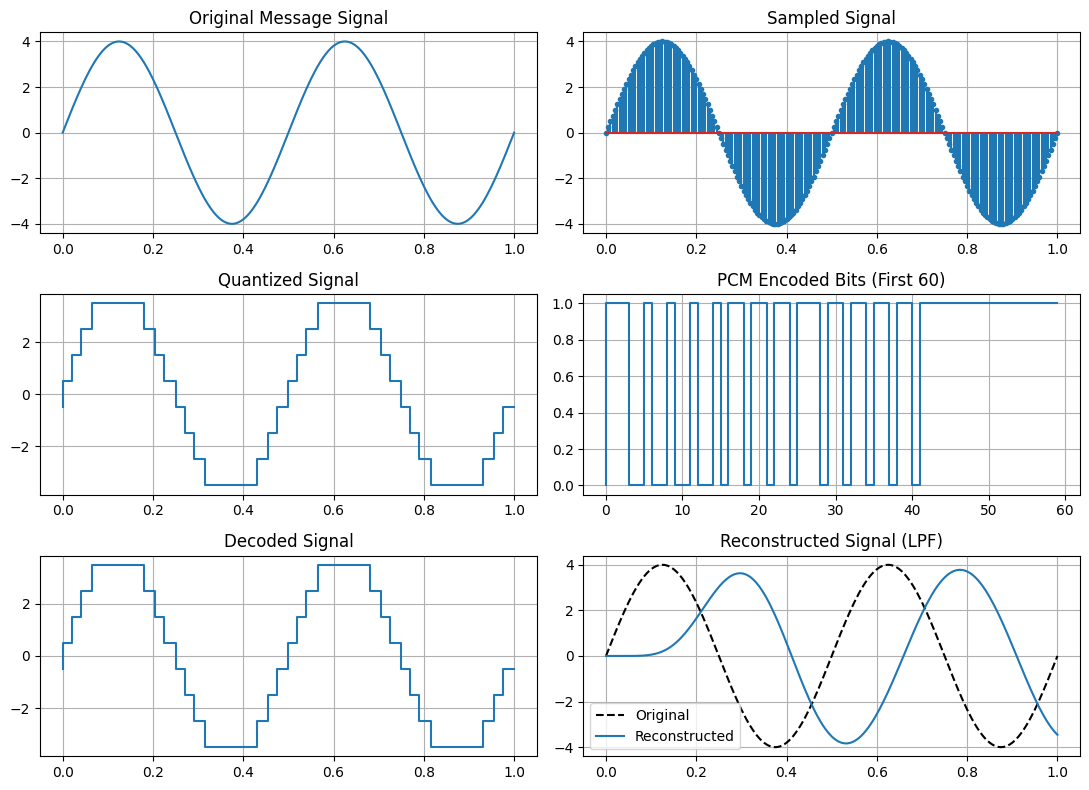

In [2]:
# 7. Plot All Waveforms
fig, ax = plt.subplots(3, 2, figsize=(11, 8))

ax[0, 0].plot(t, x)
ax[0, 0].set_title("Original Message Signal")

ax[0, 1].stem(t, x, markerfmt='.')
ax[0, 1].set_title("Sampled Signal")

ax[1, 0].step(t, xq)
ax[1, 0].set_title("Quantized Signal")

ax[1, 1].step(range(60), bits[:60])
ax[1, 1].set_title("PCM Encoded Bits (First 60)")

ax[2, 0].step(t, decoded)
ax[2, 0].set_title("Decoded Signal")

ax[2, 1].plot(t, x, 'k--', label="Original")
ax[2, 1].plot(t, reconstructed, label="Reconstructed")
ax[2, 1].legend()
ax[2, 1].set_title("Reconstructed Signal (LPF)")

# 8. Graph Formatting
for axis in ax.flat:
    axis.grid(True)

plt.tight_layout()
plt.show()

## 4. What you should observe

1. **Original message:** smooth sine wave of amplitude about $\pm4$.
2. **Sampled message:** discrete samples following the sine curve.
3. **Quantized:** staircase amplitudes at $-3.5$ to $+3.5$.
4. **PCM bits:** sequence of `0` and `1`, grouped in sets of 3.
5. **Decoded signal:** the receiver recovers the quantized amplitude levels.
6. **Reconstructed:** smooth approximation of the original sine wave, sometimes with filter start-up delay.

Expected first 12 PCM codewords (manual mapping):  
`011 100 100 100 100 101 101 101 101 110 110 110`

**Result to write:** Pulse Code Modulation and Demodulation were performed; the analog signal was sampled, quantized into 8 levels, encoded as 3-bit words, decoded and approximately reconstructed.

## 5. Viva — short answers

**Q1. What is PCM?** Digital representation of analog samples using binary codewords.  
**Q2. Sampling vs quantization?** Sampling discretizes **time**; quantization discretizes **amplitude**.  
**Q3. Why 3 bits?** $2^3=8$ quantization levels.  
**Q4. Nyquist condition?** $f_s \ge 2f_{\max}$. Here $200\gg4\,\mathrm{Hz}$.  
**Q5. What causes quantization noise?** Rounding each sample to one of the allowed levels.  
**Q6. Why use an LPF at the receiver?** To smooth the quantized waveform and suppress high-frequency components.  
**Q7. Why can the output differ from the input?** Quantization error plus practical reconstruction filtering.  
**Q8. What is the bit rate here?** $600\,\mathrm{bit/s}$.

**Practice:** Identify each waveform without reading its title, then explain the stages in order.


---

# Experiment 6 — Direct Sequence Spread Spectrum (DSSS)

**Aim (manual):** Implement Direct Sequence Spread Spectrum. The manual uses a 7-chip PN sequence followed by BPSK modulation.

## 1. Theory / working principle

**DSSS** spreads each low-rate data bit into several faster **chips** by multiplying the polar data with a pseudonoise (**PN**) sequence. The wider-band signal is then BPSK-modulated onto a carrier.

**Transmitter (manual diagram):** Binary data → polar NRZ encoder → multiply by PN code → BPSK modulator with a carrier → DSSS signal.  
**Receiver (manual diagram):** Received signal → coherent detector / local carrier → multiply by synchronized local PN sequence → integrate / decide bit.

Map binary data and PN bits to polar levels:

$$d_k=2b_k-1,\quad p_j=2c_j-1 \qquad (0\mapsto-1,\;1\mapsto+1)$$

**Spread chip value** for data bit $k$ and chip index $j$:

$$m_{k,j}=d_k p_j$$

**BPSK-modulated DSSS waveform:**

$$s(t)=m(t)\cos(2\pi f_c t)$$

With $L$ chips per data bit, the processing gain for the ideal equal-bandwidth approximation is:

$$G_p=L,\qquad G_{p,\mathrm{dB}}=10\log_{10}L$$

DSSS makes the transmitted signal occupy a wider spectrum and supports interference resistance when a receiver has the correct synchronized PN code.


## 2. Lab-manual input and example

The manual specifies:

- Input data: **`1 0 1`**
- PN sequence: **`0 0 1 0 1 1 1`** (length $L=7$)
- Polar PN: **`-1 -1 +1 -1 +1 +1 +1`**
- BPSK carrier: **$f_c=10$ cycles per bit interval**, as used by the manual's time normalization.

**How the bits spread:**

- A `1` gives the polar PN sequence unchanged.
- A `0` inverts every PN chip.
- A `1` gives the PN sequence unchanged again.

$$G_{p,\mathrm{dB}} = 10\log_{10}(7)\approx8.45\,\mathrm{dB}$$

**What is added beyond the manual's MATLAB code?** The manual shows the baseband, carrier and BPSK DSSS plots. The following Python demo also implements an **ideal synchronized despreading check**, consistent with the receiver block diagram, to print the recovered bits.


## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

Sent bits:     [1 0 1]
Received bits: [1, 0, 1]
Processing Gain: 8.45 dB


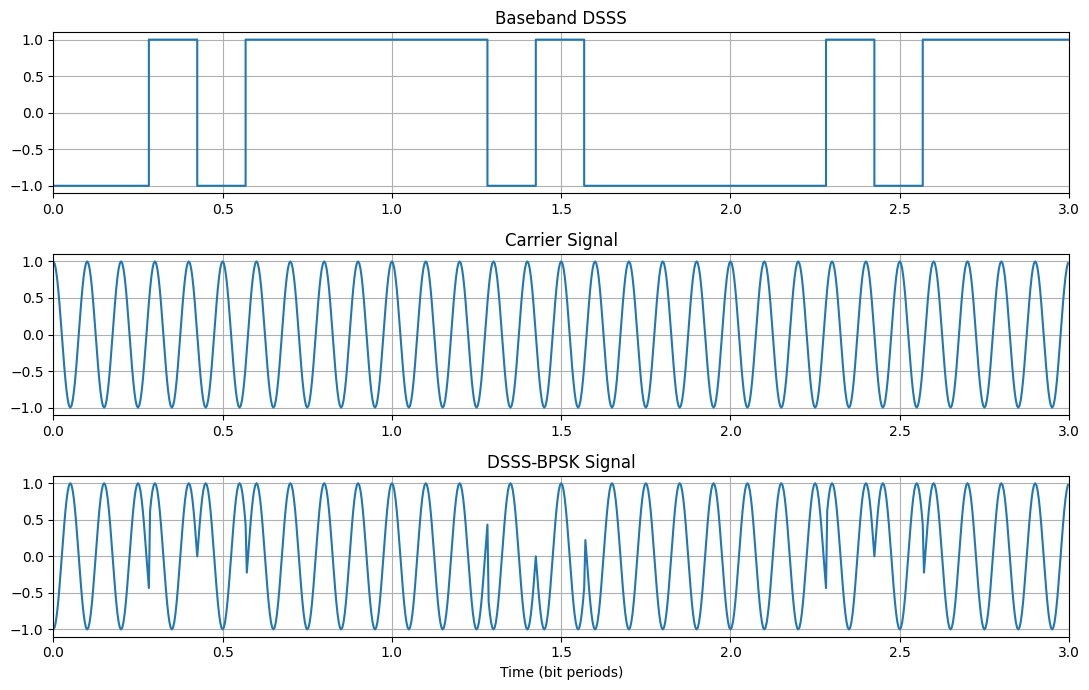

In [3]:

"""Experiment 6: DSSS using 7-chip PN code and BPSK."""
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate Binary Data and PN Code
data = np.array([1, 0, 1])
pn = np.array([0, 0, 1, 0, 1, 1, 1])
L, samples = len(pn), 40

# 2. Convert 0 to -1 and 1 to +1
message = 2 * data - 1
pn_polar = 2 * pn - 1

# 3. DSSS Spreading
message_chips = np.repeat(message, L)
pn_chips = np.tile(pn_polar, len(data))
spread = message_chips * pn_chips

# 4. BPSK Modulation with Cosine Carrier
baseband = np.repeat(spread, samples)
pn_wave = np.repeat(pn_chips, samples)
t = np.arange(len(baseband)) / (L * samples)
carrier = np.cos(2 * np.pi * 10 * t)
tx = baseband * carrier

# 5. Optional: Despreading and Data Recovery
despread = tx * carrier * pn_wave
received = []

for i in range(len(data)):
    start = i * L * samples
    end = (i + 1) * L * samples
    bit = int(np.sum(despread[start:end]) > 0)
    received.append(bit)

# 6. Display Results
print("Sent bits:    ", data)
print("Received bits:", received)
print(f"Processing Gain: {10*np.log10(L):.2f} dB")

# 7. Plot DSSS Waveforms
fig, ax = plt.subplots(3, 1, figsize=(11, 7))

ax[0].step(t, baseband)
ax[0].set_title("Baseband DSSS")

ax[1].plot(t, carrier)
ax[1].set_title("Carrier Signal")

ax[2].plot(t, tx)
ax[2].set_title("DSSS-BPSK Signal")

for a in ax:
    a.grid(True)
    a.set_xlim(0, len(data))

ax[-1].set_xlabel("Time (bit periods)")
plt.tight_layout()
plt.show()


## 4. Expected output and interpretation

- Plot 1, **Baseband DSSS**: the polar value may change multiple times inside one original data bit because of the 7-chip PN code.
- Plot 2, **Carrier**: a sinusoidal carrier of constant frequency.
- Plot 3, **DSSS-BPSK**: carrier phase changes according to the spread chip signs.
- Printed result: sent bits **`[1 0 1]`** and recovered bits **`[1, 0, 1]`** (ideal synchronized receiver).
- Processing gain: **7** or about **8.45 dB**.

**Result to write:** The binary input sequence was spread with the PN sequence and modulated using BPSK, producing a DSSS signal. Under ideal receiver synchronization, the original sequence was recovered.

## 5. Viva — short answers

**Q1. What is DSSS?** A spread-spectrum technique that multiplies data with a faster PN chip sequence.  
**Q2. What is a chip?** One element of the higher-rate spreading sequence.  
**Q3. Why use PN code?** For controlled spreading and synchronized despreading.  
**Q4. Data bit vs chip?** One data bit is represented by several PN chips.  
**Q5. What is a spreading factor here?** $L=7$ chips per bit.  
**Q6. How does the receiver recover data?** It uses a synchronized local PN sequence and coherent detection/correlation.  
**Q7. What if PN sequences are not synchronized?** Despreading and data recovery degrade.  
**Q8. DSSS vs FHSS?** DSSS spreads through code multiplication; FHSS changes carrier frequency over time.

**Practice:** Explain why an input `0` produces the *negative* of the PN pattern.


---

# Experiment 7 — Frequency Hopping Spread Spectrum (FHSS)

**Aim (manual):** Implement Frequency Hopping Spread Spectrum in MATLAB.

## 1. Theory / working principle

**FHSS** changes the carrier frequency among a set of permitted frequencies according to a hopping sequence. The transmitter and receiver must follow the same hopping pattern and timing.

**Transmitter (manual block diagram):** Binary data → M-ary FSK modulator → mixer with PN-controlled frequency synthesizer → FH/MFSK signal.  
**Receiver (manual block diagram):** Mix with synchronized local synthesizer → band-pass filter → noncoherent M-ary FSK detector → estimated binary data.

The *program in the manual* actually demonstrates a **BPSK signal multiplied by a frequency-hopping waveform**, rather than a full M-ary FSK detector. This exam-ready Python notebook follows that simulation style: it uses a fixed, reproducible hop sequence and adds an ideal recovery check.

### Essential mathematical model for this demonstration

Polar data:

$$d_k = 2b_k - 1$$

Hop frequency chosen at time slot $k$:

$$f_h(k)\in\{f_1,f_2,\dots,f_M\}$$

BPSK signal and hopping signal:

$$s_{\mathrm{BPSK}}(t)=d_k\cos(2\pi f_0 t),\qquad h_k(t)=\cos(2\pi f_h(k)t)$$

Waveform shown by this **multiplication-based demonstration**:

$$s_{\mathrm{demo}}(t)=s_{\mathrm{BPSK}}(t)\,h_k(t)$$

The hop interval and hop rate are related by:

$$R_h=\frac{1}{T_h}$$

**Important distinction:** Multiplying two cosines creates sum-and-difference frequency components. A full frequency-hopping radio is more than this classroom simulation.


## 2. Input, hops and manual correspondence

This compact notebook uses **10 data bits** so you can explain every step easily. The manual's longer MATLAB example uses **20 random bits** and an older random-integer function; therefore your exact bit values and plots need not match the manual's random run.

| Quantity | This reproducible demo |
|---|---|
| Binary data | `1 0 1 1 0 0 1 0 1 1` |
| Available hop frequencies | `1, 2, 3, 4, 6, 12, 24` cycles/bit |
| Hop indices | `7, 3, 5, 1, 4, 6, 2, 7, 2, 5` |
| Chosen frequencies | `24, 3, 6, 1, 4, 12, 2, 24, 2, 6` |
| Plot count | 4 |

**Why fixed hops?** They serve the same visual learning goal and produce identical expected plots on every run. They **represent** a chosen hopping sequence; they are **not** a generated PN/LFSR sequence. This notebook uses an *ideal, synchronized* dehopping detector as an additional correctness check.


## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

Hop Frequencies: [24  3  6  1  4 12  2 24  2  6]
Sent Bits:       [1 0 1 1 0 0 1 0 1 1]
Recovered Bits:  [1, 0, 1, 1, 0, 0, 1, 0, 1, 1]


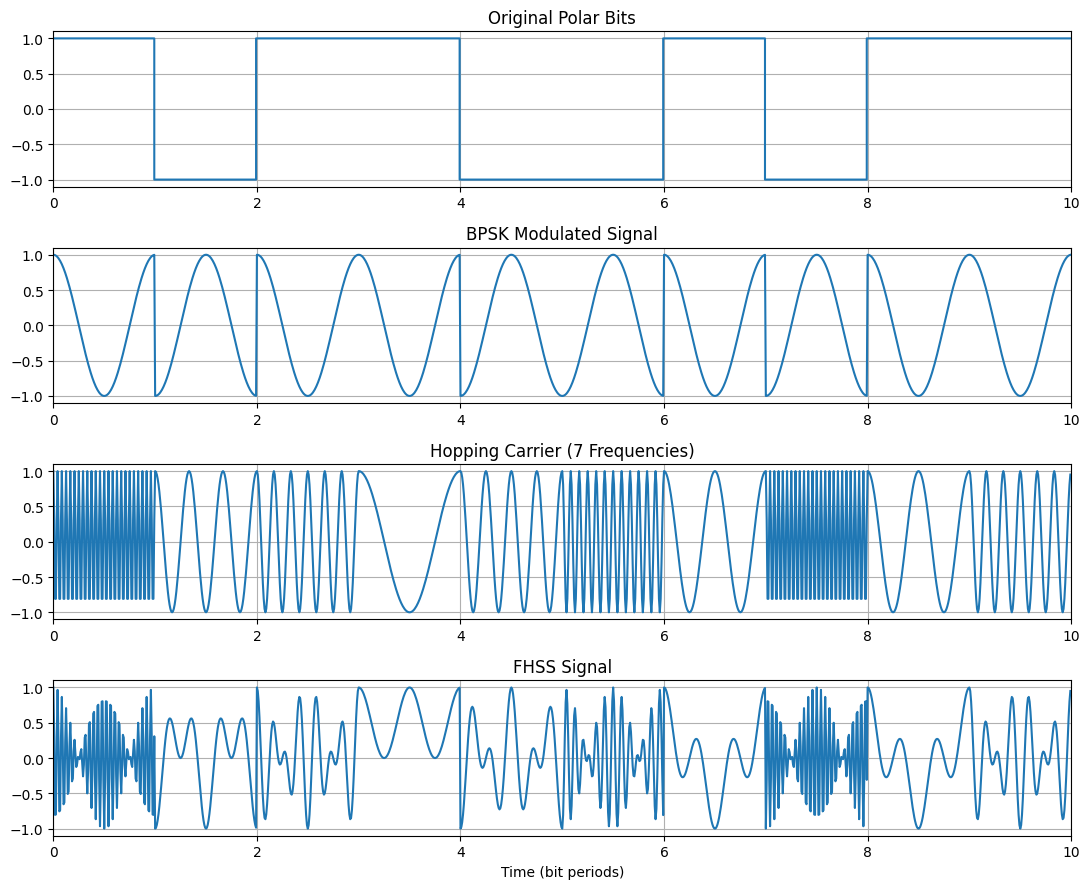

In [4]:

"""Experiment 7: FHSS using BPSK and seven hopping frequencies."""
import numpy as np
import matplotlib.pyplot as plt

# 1. Message bits, hop order and available frequencies
bits = np.array([1, 0, 1, 1, 0, 0, 1, 0, 1, 1])
hop_index = np.array([7, 3, 5, 1, 4, 6, 2, 7, 2, 5])
freq = np.array([1, 2, 3, 4, 6, 12, 24])  # cycles per bit period
N = 120                                       # samples per bit (one hop)
t_bit = np.arange(N) / N                      # time for one bit
t = np.arange(len(bits) * N) / N              # time for all bits

# 2. Binary Data -> Polar Bits -> BPSK Carrier
polar = np.repeat(2 * bits - 1, N)
base_carrier = np.tile(np.cos(2 * np.pi * t_bit), len(bits))
bpsk = polar * base_carrier

# 3. Frequency-Hopping Carrier
hop_carrier = np.zeros_like(t)

for i, hop in enumerate(hop_index):
    start, end = i * N, (i + 1) * N
    hop_carrier[start:end] = np.cos(2 * np.pi * freq[hop-1] * t_bit)

# 4. FHSS Modulation (Mix BPSK with Hopping Carrier)
fhss = bpsk * hop_carrier

# 5. Optional: De-hopping and Data Recovery
received = []
for i in range(len(bits)):
    start, end = i * N, (i + 1) * N
    score = np.sum(fhss[start:end] * hop_carrier[start:end] * base_carrier[start:end])
    received.append(int(score > 0))

# 6. Display Results
print("Hop Frequencies:", freq[hop_index-1])
print("Sent Bits:      ", bits)
print("Recovered Bits: ", received)

# 7. Plot FHSS Waveforms
fig, ax = plt.subplots(4, 1, figsize=(11, 9))

ax[0].step(t, polar)
ax[0].set_title("Original Polar Bits")

ax[1].plot(t, bpsk)
ax[1].set_title("BPSK Modulated Signal")

ax[2].plot(t, hop_carrier)
ax[2].set_title("Hopping Carrier (7 Frequencies)")

ax[3].plot(t, fhss)
ax[3].set_title("FHSS Signal")

for a in ax:
    a.grid(True)
    a.set_xlim(0, len(bits))

ax[-1].set_xlabel("Time (bit periods)")
plt.tight_layout()
plt.show()


## 4. Expected output and interpretation

1. **Original polar bits:** high for a `1`, low for a `0`.
2. **BPSK signal:** sinusoidal carrier with a $180^\circ$ phase flip for polar `-1` bits.
3. **Hopping carrier:** waveform oscillation rate changes from slot to slot, following the 7-frequency set.
4. **FHSS signal:** mixed waveform changes with the data and the hopping carrier.

You should see **recovered bits `1011001011`**, identical to the input, in the ideal no-noise model. Explain the **change of hopping rate/frequency**, not the exact appearance of every oscillation.

**Result to write:** A sequence of data bits was transmitted with a hopping-frequency waveform using seven frequencies. The receiver recovered the input correctly under ideal synchronization.

## 5. Viva — short answers

**Q1. What is FHSS?** Spread spectrum using a carrier that changes frequency in a synchronized pattern.  
**Q2. Who controls the hops?** A PN-controlled frequency synthesizer in the conceptual system.  
**Q3. Why hop frequencies?** To improve resilience against narrowband interference/jamming and share spectrum.  
**Q4. What is the hop rate?** Number of frequency changes per second, $R_h=1/T_h$.  
**Q5. How does the receiver recover data?** By synchronized dehopping followed by signal detection.  
**Q6. What happens if synchronization fails?** The receiver follows the wrong hop and may fail to demodulate.  
**Q7. Fast vs slow FHSS?** In fast hopping there are multiple hops per symbol; in slow hopping there can be multiple symbols per hop.  
**Q8. FHSS vs DSSS?** FHSS varies carrier frequency; DSSS multiplies data by a rapid PN chip sequence.

**Practice:** On the third plot, point out two adjacent intervals with visibly different carrier frequencies.


---

# Experiment 12 — Convolutional Codes

**Aim (manual):** Implement a convolutional encoder in MATLAB. The manual specifically codes a **$(2,1,2)$ encoder**.

## 1. Theory / working principle

A **convolutional encoder** forms multiple output bits from the current input bit **and the previous stored bits**, using shift registers (delay elements) and XOR gates.

For this manual's $(n,k,m)=(2,1,2)$ encoder:

- $k=1$: one input bit enters per step.
- $n=2$: two coded output bits are produced per step.
- $m=2$: two memory (flip-flop) elements retain past bits.
- **Code rate:** $R=k/n=1/2$.
- **Constraint length:** $K=m+1=3$ (the current bit plus two previous bits).

The XOR wiring in the manual corresponds to these generator polynomials:

$$g_1(D)=1+D+D^2,\qquad g_2(D)=1+D^2$$

For the current input $u_i$ and previous stored bits $u_{i-1}$ and $u_{i-2}$:

$$c_1(i)=u_i\oplus u_{i-1}\oplus u_{i-2}$$

$$c_2(i)=u_i\oplus u_{i-2}$$

Here $\oplus$ means **XOR** (addition modulo 2): $0\oplus0=0$, $0\oplus1=1$, $1\oplus1=0$.

**Encoder flow:** current bit and shift-register bits → XOR connections → 2-bit coded output → shift the new bit into the memory.


## 2. Worked example from the manual

The manual uses the message **`1 0 1 1`**. It appends **two zeros** to flush the two memory elements back toward the zero state:

$$\text{encoder input}=1\;0\;1\;1\;0\;0$$

| Current input $u_i$ | Register ($u_{i-1}$,$u_{i-2}$) **before** step | $c_1$ | $c_2$ | Output pair |
|---:|:---:|---:|---:|:---:|
| 1 | 0,0 | 1 | 1 | `11` |
| 0 | 1,0 | 1 | 0 | `10` |
| 1 | 0,1 | 0 | 0 | `00` |
| 1 | 1,0 | 0 | 1 | `01` |
| 0 | 1,1 | 0 | 1 | `01` |
| 0 | 0,1 | 1 | 1 | `11` |

Output pairs: `11 10 00 01 01 11`  
Serialized encoded bits: **`111000010111`** (12 bits, including termination).

**Manual correspondence:** the manual prints the **code vector `c`** as six 2-bit rows. The two illustrative input/output plots here are extra visual study aids, not required manual plots. This experiment is encoder-only: the manual does **not** implement Viterbi decoding.


## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

Encoder input: [1, 0, 1, 1, 0, 0]
Output pairs: 11 10 00 01 01 11
Encoded stream: 111000010111


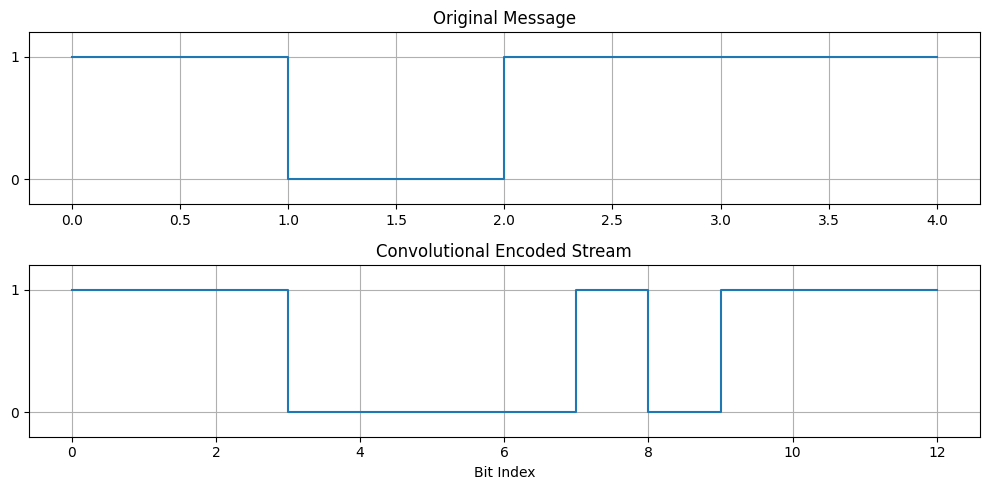

In [5]:

"""Experiment 12: (2,1,2) Convolutional Encoder."""
import matplotlib.pyplot as plt

# 1. Original Message and Two Terminating Zeros
message = [1, 0, 1, 1]
input_bits = message + [0, 0]

# 2. Initialize Two Shift Registers
d1 = d2 = 0
pairs = []

# 3. Convolutional Encoding using XOR
for bit in input_bits:
    c1 = bit ^ d1 ^ d2     # Generator g1 = 111
    c2 = bit ^ d2          # Generator g2 = 101
    pairs.append([c1, c2])
    d2, d1 = d1, bit       # Shift registers

# 4. Convert Output Pairs into Serial Bit Stream
encoded = [b for pair in pairs for b in pair]

# 5. Display Results
print("Encoder input:", input_bits)
print("Output pairs:", ' '.join(''.join(map(str, p)) for p in pairs))
print("Encoded stream:", ''.join(map(str, encoded)))

# 6. Plot Original and Encoded Signals
fig, ax = plt.subplots(2, 1, figsize=(10, 5))

ax[0].step(range(len(message)+1), message + [message[-1]], where='post')
ax[0].set_title("Original Message")

ax[1].step(range(len(encoded)+1), encoded + [encoded[-1]], where='post')
ax[1].set_title("Convolutional Encoded Stream")

for a in ax:
    a.set_ylim(-0.2, 1.2)
    a.set_yticks([0, 1])
    a.grid(True)

ax[1].set_xlabel("Bit Index")
plt.tight_layout()
plt.show()


## 4. Expected output and interpretation

- Printed **encoder input**: `[1, 0, 1, 1, 0, 0]`.
- Printed **output pairs**: `11 10 00 01 01 11`.
- Printed **encoded stream**: `111000010111`.
- Plot 1: the original four input bits; Plot 2: 12 serialized output bits.

**Result to write:** A $(2,1,2)$ convolutional encoder was implemented. For input `1011` followed by two termination zeros, it produced `11 10 00 01 01 11` using shift registers and XOR operations.

## 5. Viva — short answers

**Q1. What is convolutional coding?** Encoding each input using the current input bit and previous stored bits.  
**Q2. Code rate?** $k/n=1/2$, i.e., two output bits per one input bit.  
**Q3. What is memory order here?** $m=2$ flip-flops.  
**Q4. Constraint length?** $K=m+1=3$.  
**Q5. Why append two zeros?** To terminate/flush the encoder's two memory elements.  
**Q6. What is XOR?** Output `1` if an odd number of inputs are `1`.  
**Q7. What are the generators?** $g_1=111$, $g_2=101$ (binary tap patterns).  
**Q8. How many coded bits result?** Six processed inputs $\times$ two output bits = **12** encoded bits.  
**Q9. What decoder is commonly associated with convolutional codes?** Viterbi decoding; it is **not implemented** in the supplied manual's Exp 12.

**Practice:** Derive the first 3 output pairs from the XOR equations before running the cell.


---

# Master Benchmark Summary & Viva Reference

| Exp # | Experiment Title | Key Parameters | Input | Output / Key Benchmark Metric |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Pulse Code Modulation (PCM)** | $A=4\text{ V}, f_m=2\text{ Hz}, f_s=200\text{ Hz}$, $L=8$ levels ($3\text{ bits}$) | Analog Sine $x(t)$ | First 12 words: `011 100 100 100 100 101 101 101 101 110 110 110`, Bit rate = $600\text{ bps}$, MSE $\approx 0.1005$ |
| **6** | **Direct Sequence Spread Spectrum (DSSS)** | 7-chip PN sequence `[0, 0, 1, 0, 1, 1, 1]`, $f_c=10\text{ cycles/bit}$ | `1 0 1` | Recovered: `1 0 1`, Processing Gain = $7\ (8.45\text{ dB})$, Zero bit errors |
| **7** | **Frequency Hopping Spread Spectrum (FHSS)** | 7 hop frequencies `[1, 2, 3, 4, 6, 12, 24]\text{ cycles/bit}$, $N=120\text{ samples/bit}$ | `1 0 1 1 0 0 1 0 1 1` | Recovered: `1 0 1 1 0 0 1 0 1 1`, 100% matched coherent dehopping |
| **12** | **(2, 1, 2) Convolutional Codes** | Rate $R=1/2$, Constraint $K=3$, $g_1=111_2, g_2=101_2$, Tail `00` | `1 0 1 1` $\to$ `1 0 1 1 0 0` | Pairs: `11 10 00 01 01 11`, Serial stream: `111000010111` |

---
*Created for ICT-4206 Telecommunication Laboratory examination preparation.*